In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
boundary_path = Path("../data/processed/sahiwal_boundary.geojson")

sahiwal = gpd.read_file(boundary_path)

print("District:", sahiwal.iloc[0]["shapeName"])
print("CRS:", sahiwal.crs)
print("Geometry type:", sahiwal.geometry.iloc[0].geom_type)
print("Boundary loaded:", not sahiwal.empty)

District: Sahiwal
CRS: EPSG:4326
Geometry type: Polygon
Boundary loaded: True


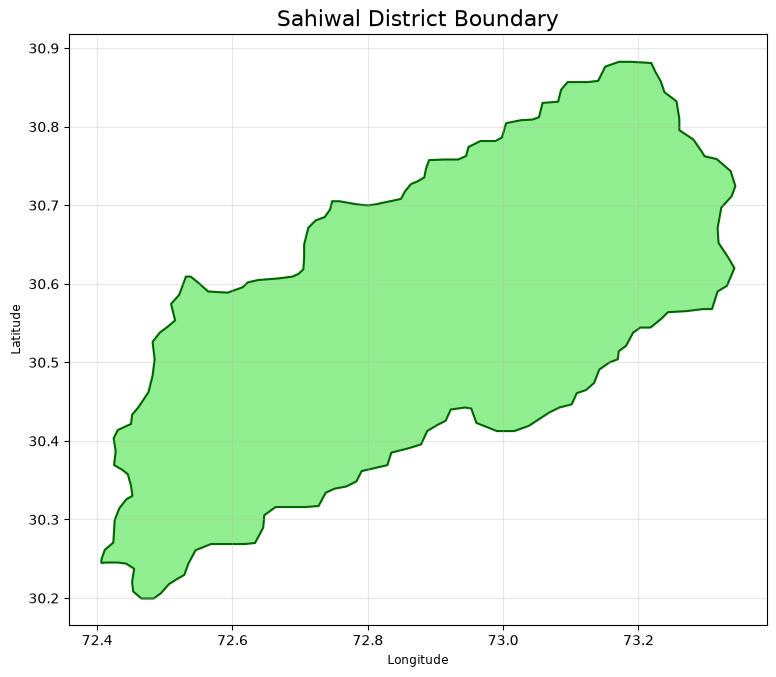

In [3]:
fig, ax = plt.subplots(figsize=(9, 9))

sahiwal.plot(
    ax=ax,
    facecolor="lightgreen",
    edgecolor="darkgreen",
    linewidth=1.5
)

ax.set_title("Sahiwal District Boundary", fontsize=16)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(True, alpha=0.3)

plt.show()

# SoilSenseAI — Sahiwal Soil Analysis

## Objective
Explore SoilGrids soil properties across Sahiwal district.

## First property
Soil pH (0–5 cm depth, median prediction).

## Data source
SoilGrids 2.0 — ISRIC World Soil Information.

Resolution: 250 metres.

In [4]:
from owslib.wcs import WebCoverageService

wcs_url = "https://maps.isric.org/mapserv?map=/map/phh2o.map"

wcs = WebCoverageService(
    wcs_url,
    version="2.0.1"
)

print("Connected to SoilGrids!")

Connected to SoilGrids!


In [5]:
coverages = list(wcs.contents.keys())

ph_layers = [
    layer for layer in coverages
    if layer.startswith("phh2o_0-5cm")
]

print("Available pH layers:")
for layer in ph_layers:
    print(layer)

Available pH layers:
phh2o_0-5cm_Q0.05
phh2o_0-5cm_Q0.5
phh2o_0-5cm_Q0.95
phh2o_0-5cm_mean
phh2o_0-5cm_uncertainty


In [6]:
coverage_id = "phh2o_0-5cm_Q0.5"

coverage = wcs.contents[coverage_id]

print("Coverage:", coverage_id)

print("\nSupported formats:")
print(coverage.supportedFormats)

print("\nSupported coordinate systems:")
print(coverage.supportedCRS)

Coverage: phh2o_0-5cm_Q0.5

Supported formats:
['image/tiff', 'image/png', 'image/jpeg', 'image/png; mode=8bit', 'image/vnd.jpeg-png', 'image/vnd.jpeg-png8']

Supported coordinate systems:
[]


In [7]:
# Get Sahiwal's geographic bounds
west, south, east, north = sahiwal.total_bounds

print("Sahiwal bounding box:")
print("West:", west)
print("South:", south)
print("East:", east)
print("North:", north)

Sahiwal bounding box:
West: 72.40530325913818
South: 30.200059692500872
East: 73.34250139442389
North: 30.883223425520725


In [8]:
print("SoilGrids coverage bounding boxes:")

for bbox in coverage.boundingboxes:
    print(bbox)

SoilGrids coverage bounding boxes:
{'nativeSrs': 'http://www.opengis.net/def/crs/EPSG/0/152160', 'bbox': (-19949750.0, -6147500.0, 19861750.0, 8361000.0)}


In [9]:
soilgrids_crs = (
    "+proj=igh +datum=WGS84 +units=m +no_defs +towgs84=0,0,0"
)

sahiwal_projected = sahiwal.to_crs(soilgrids_crs)

west_sg, south_sg, east_sg, north_sg = sahiwal_projected.total_bounds

print("Sahiwal bounds in SoilGrids projection:")
print("West:", west_sg)
print("South:", south_sg)
print("East:", east_sg)
print("North:", north_sg)

Sahiwal bounds in SoilGrids projection:
West: 7412702.138647378
South: 3361855.2668956635
East: 7491531.6341720745
North: 3437904.705783865


In [25]:
from pathlib import Path

coverage_id = "phh2o_0-5cm_Q0.5"

subsets = [
    ("X", float(west_sg), float(east_sg)),
    ("Y", float(south_sg), float(north_sg))
]

print("Requesting soil pH data from SoilGrids...")

response = wcs.getCoverage(
    identifier=coverage_id,
    crs=soilgrids_crs_url,
    subsets=subsets,
    resx=250,
    resy=250,
    format="image/tiff"
)

output_path = Path("../data/raw/sahiwal_phh2o_0-5cm_Q0.5.tif")

with open(output_path, "wb") as file:
    file.write(response.read())

print("Download complete!")
print("File size:", round(output_path.stat().st_size / 1024, 2), "KB")

Requesting soil pH data from SoilGrids...


NameError: name 'soilgrids_crs_url' is not defined

In [12]:
import rasterio

raster_path = Path("../data/raw/sahiwal_phh2o_0-5cm_Q0.5.tif")

with rasterio.open(raster_path) as src:
    print("Driver:", src.driver)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Data type:", src.dtypes)
    print("NoData value:", src.nodata)

Driver: GTiff
Width: 315
Height: 304
Bands: 1
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Interrupted_Goode_Homolosine"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Resolution: (250.25236674506442, 250.16262792171634)
Bounds: BoundingBox(left=7412702.138647378, bottom=3361855.266895663, right=7491531.634172074, top=3437904.705783865)
Data type: ('int16',)
NoData value: None


In [13]:
with rasterio.open(raster_path) as src:

    data = src.read(1, masked=True)

    print("Minimum value:", data.min())
    print("Maximum value:", data.max())
    print("Mean value:", round(float(data.mean()), 2))
    print("Valid pixels:", data.count())
    print("Missing pixels:", data.size - data.count())

    print("\nRaster metadata:")
    print(src.tags())

Minimum value: 0
Maximum value: 82
Mean value: 78.28
Valid pixels: 95760
Missing pixels: 0

Raster metadata:
{'TIFFTAG_XRESOLUTION': '72', 'TIFFTAG_YRESOLUTION': '72', 'TIFFTAG_RESOLUTIONUNIT': '2 (pixels/inch)', 'AREA_OR_POINT': 'Area'}


In [14]:
import numpy as np

unique_values, counts = np.unique(
    data.compressed(),
    return_counts=True
)

print("Number of unique values:", len(unique_values))
print("\nLowest 10 values and their frequencies:")

for value, count in zip(unique_values[:10], counts[:10]):
    print(f"Value: {value}, Pixels: {count}")

print("\nHighest 10 values and their frequencies:")

for value, count in zip(unique_values[-10:], counts[-10:]):
    print(f"Value: {value}, Pixels: {count}")

Number of unique values: 6

Lowest 10 values and their frequencies:
Value: 0, Pixels: 2073
Value: 78, Pixels: 10
Value: 79, Pixels: 704
Value: 80, Pixels: 91401
Value: 81, Pixels: 1558
Value: 82, Pixels: 14

Highest 10 values and their frequencies:
Value: 0, Pixels: 2073
Value: 78, Pixels: 10
Value: 79, Pixels: 704
Value: 80, Pixels: 91401
Value: 81, Pixels: 1558
Value: 82, Pixels: 14


In [15]:
from rasterio.mask import mask

with rasterio.open(raster_path) as src:

    # Convert Sahiwal boundary into the raster's CRS
    sahiwal_raster_crs = sahiwal.to_crs(src.crs)

    # Mask pixels outside the actual district boundary
    clipped, transform = mask(
        src,
        sahiwal_raster_crs.geometry,
        crop=False,
        filled=False
    )

    district_data = clipped[0]
    values = district_data.compressed()

    print("Pixels inside Sahiwal:", len(values))
    print("Zero values inside Sahiwal:", np.sum(values == 0))
    print("Non-zero pixels:", np.sum(values != 0))
    print("Minimum non-zero value:", values[values > 0].min())
    print("Maximum value:", values.max())

Pixels inside Sahiwal: 50158
Zero values inside Sahiwal: 1351
Non-zero pixels: 48807
Minimum non-zero value: 78
Maximum value: 82


In [16]:
# Count values only inside Sahiwal
unique, counts = np.unique(values, return_counts=True)

print("Sahiwal pH raster distribution:")

for value, count in zip(unique, counts):
    print(f"Stored value: {value}, Pixels: {count}")

# Exclude zero-valued cells for provisional statistics
valid_values = values[values > 0]

ph_values = valid_values / 10

print("\nProvisional pH statistics:")
print("Valid pixels:", len(ph_values))
print("Mean pH:", round(ph_values.mean(), 2))
print("Minimum pH:", round(ph_values.min(), 2))
print("Maximum pH:", round(ph_values.max(), 2))
print("Median pH:", round(np.median(ph_values), 2))

Sahiwal pH raster distribution:
Stored value: 0, Pixels: 1351
Stored value: 78, Pixels: 2
Stored value: 79, Pixels: 311
Stored value: 80, Pixels: 48112
Stored value: 81, Pixels: 371
Stored value: 82, Pixels: 11

Provisional pH statistics:
Valid pixels: 48807
Mean pH: 8.0
Minimum pH: 7.8
Maximum pH: 8.2
Median pH: 8.0


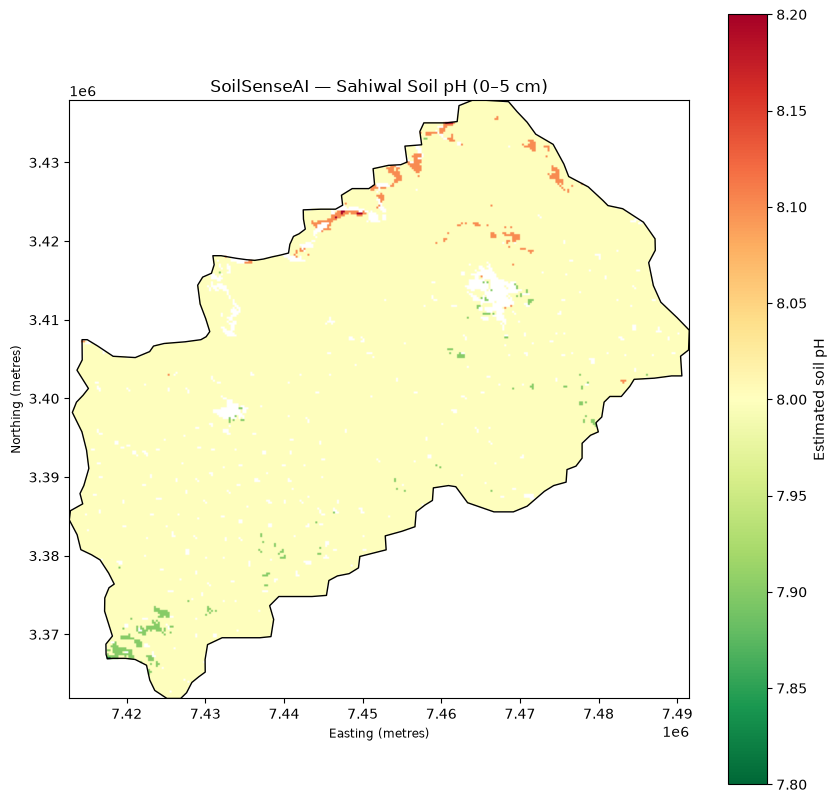

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.plot import show

# Mask zero values provisionally; retain only non-zero estimates
ph_map = np.ma.masked_where(
    district_data.mask | (district_data.data == 0),
    district_data.data / 10
)

fig, ax = plt.subplots(figsize=(10, 10))

show(
    ph_map,
    transform=transform,
    ax=ax,
    cmap="RdYlGn_r"
)

sahiwal_raster_crs.boundary.plot(
    ax=ax,
    edgecolor="black",
    linewidth=1
)

plt.colorbar(
    ax.images[0],
    ax=ax,
    label="Estimated soil pH"
)

ax.set_title("SoilSenseAI — Sahiwal Soil pH (0–5 cm)")
ax.set_xlabel("Easting (metres)")
ax.set_ylabel("Northing (metres)")

plt.show()

In [18]:
import rasterio
import numpy as np

tif_path = "../data/raw/out.tif"

with rasterio.open(tif_path) as src:
    data = src.read(1, masked=True)

    print("Dimensions:", src.width, "x", src.height)
    print("Bands:", src.count)
    print("Data type:", src.dtypes)
    print("NoData:", src.nodata)
    print("Minimum:", data.min())
    print("Maximum:", data.max())
    print("Mean:", data.mean())
    print("Unique values:", len(np.unique(data.compressed())))

Dimensions: 415 x 286
Bands: 1
Data type: ('int16',)
NoData: None
Minimum: 0
Maximum: 82
Mean: 76.50348807818688
Unique values: 10


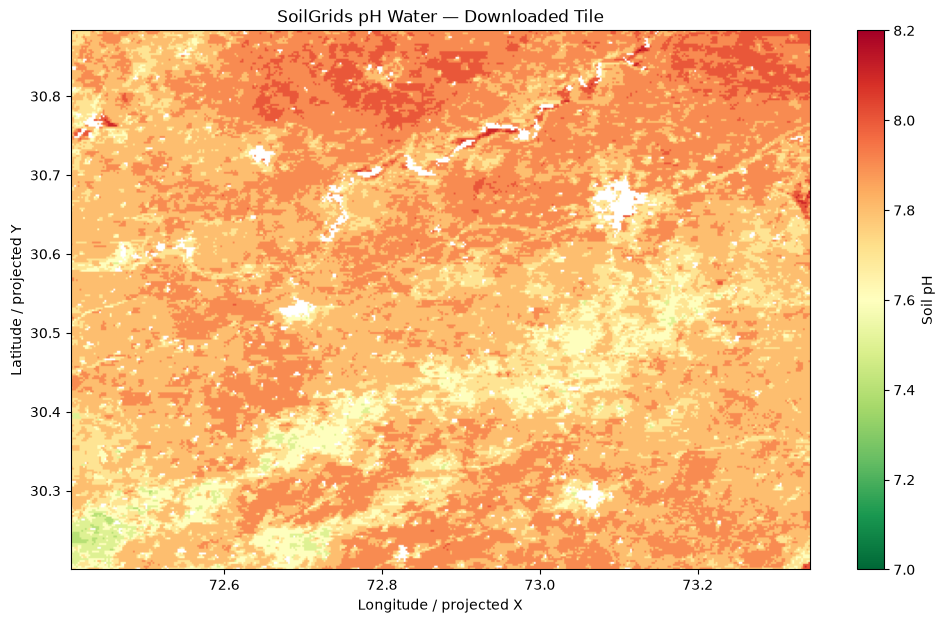

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio

with rasterio.open(tif_path) as src:
    data = src.read(1)
    bounds = src.bounds

display_data = np.ma.masked_where(data == 0, data / 10)

plt.figure(figsize=(12, 7))

plt.imshow(
    display_data,
    cmap="RdYlGn_r",
    vmin=7.0,
    vmax=8.2,
    extent=[bounds.left, bounds.right, bounds.bottom, bounds.top]
)

plt.colorbar(label="Soil pH")
plt.title("SoilGrids pH Water — Downloaded Tile")
plt.xlabel("Longitude / projected X")
plt.ylabel("Latitude / projected Y")
plt.show()

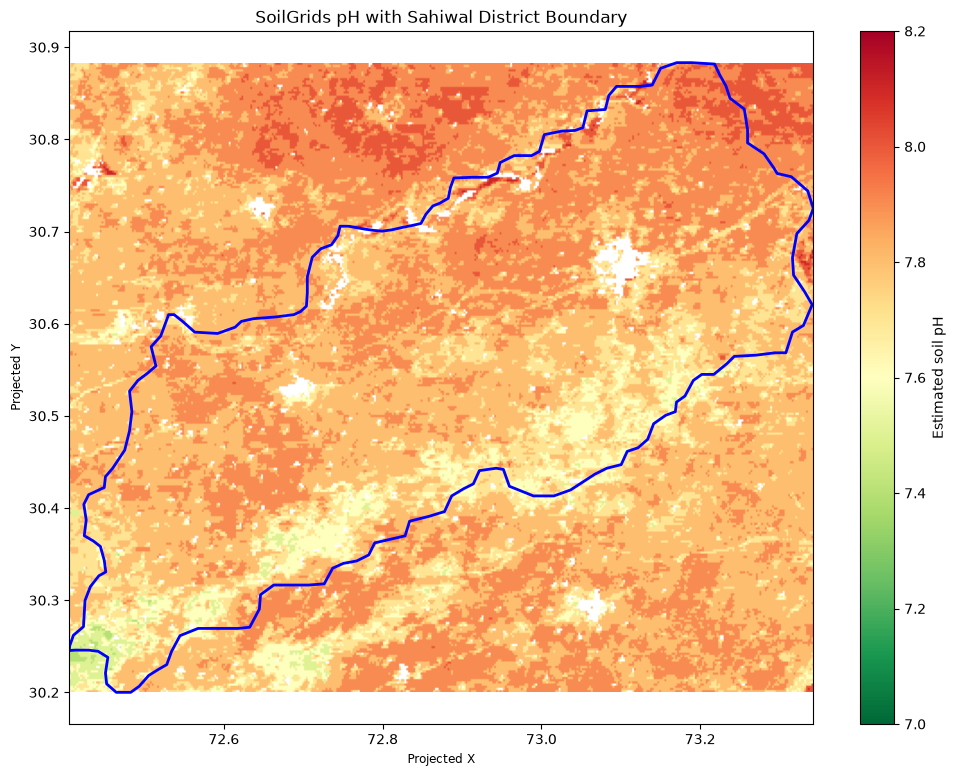

In [20]:
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import numpy as np

boundary_path = "../data/processed/sahiwal_boundary.geojson"

with rasterio.open(tif_path) as src:
    data = src.read(1)
    raster_crs = src.crs
    bounds = src.bounds

sahiwal_boundary = gpd.read_file(boundary_path)

# Transform boundary into raster CRS
sahiwal_projected = sahiwal_boundary.to_crs(raster_crs)

# Mask zero values provisionally
display_data = np.ma.masked_where(data == 0, data / 10)

fig, ax = plt.subplots(figsize=(12, 9))

img = ax.imshow(
    display_data,
    extent=[
        bounds.left, bounds.right,
        bounds.bottom, bounds.top
    ],
    origin="upper",
    cmap="RdYlGn_r",
    vmin=7.0,
    vmax=8.2
)

sahiwal_projected.boundary.plot(
    ax=ax,
    edgecolor="blue",
    linewidth=2
)

plt.colorbar(img, ax=ax, label="Estimated soil pH")
ax.set_title("SoilGrids pH with Sahiwal District Boundary")
ax.set_xlabel("Projected X")
ax.set_ylabel("Projected Y")

plt.show()

In [21]:
from rasterio.mask import mask
import rasterio
import numpy as np

with rasterio.open(tif_path) as src:

    sahiwal_projected = sahiwal.to_crs(src.crs)

    clipped, transform = mask(
        src,
        sahiwal_projected.geometry,
        crop=True,
        filled=False
    )

    new_values = clipped[0].compressed()

# Provisionally exclude zero values
new_values = new_values[new_values != 0]

# Convert stored values to actual pH
new_ph = new_values / 10

print("New SoilGrids Mean Dataset")
print("--------------------------")
print("Valid pixels:", len(new_ph))
print("Minimum pH:", new_ph.min())
print("Maximum pH:", new_ph.max())
print("Mean pH:", new_ph.mean())
print("Median pH:", np.median(new_ph))
print("Unique values:", np.unique(new_ph))

New SoilGrids Mean Dataset
--------------------------
Valid pixels: 53075
Minimum pH: 7.4
Maximum pH: 8.1
Mean pH: 7.798848798869525
Median pH: 7.8
Unique values: [7.4 7.5 7.6 7.7 7.8 7.9 8.  8.1]


In [22]:
unique, counts = np.unique(new_ph, return_counts=True)

for value, count in zip(unique, counts):
    percentage = (count / len(new_ph)) * 100
    print(f"pH {value:.1f}: {count:6} pixels ({percentage:.2f}%)")

pH 7.4:     56 pixels (0.11%)
pH 7.5:    576 pixels (1.09%)
pH 7.6:   3981 pixels (7.50%)
pH 7.7:   8492 pixels (16.00%)
pH 7.8:  23109 pixels (43.54%)
pH 7.9:  15969 pixels (30.09%)
pH 8.0:    850 pixels (1.60%)
pH 8.1:     42 pixels (0.08%)


In [23]:
import rasterio

original_path = "../data/raw/sahiwal_phh2o_0-5cm_Q0.5.tif"

for name, path in [
    ("Original Q0.5", original_path),
    ("Downloaded Mean", tif_path)
]:
    with rasterio.open(path) as src:
        print(f"\n{name}")
        print("CRS:", src.crs)
        print("Dimensions:", src.width, "x", src.height)
        print("Resolution:", src.res)
        print("Bounds:", src.bounds)


Original Q0.5
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Interrupted_Goode_Homolosine"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Dimensions: 315 x 304
Resolution: (250.25236674506442, 250.16262792171634)
Bounds: BoundingBox(left=7412702.138647378, bottom=3361855.266895663, right=7491531.634172074, top=3437904.705783865)

Downloaded Mean
CRS: EPSG:4326
Dimensions: 415 x 286
Resolution: (0.0022583132530120667, 0.0023884615384615463)
Bounds: BoundingBox(left=72.40529999999998, bottom=30.200099999999996, right=73.34249999999999, top=30.8832)


In [27]:
import rasterio
import numpy as np

from rasterio.warp import reproject, Resampling
from rasterio.features import geometry_mask

original_path = "../data/raw/sahiwal_phh2o_0-5cm_Q0.5.tif"

with rasterio.open(original_path) as original, \
     rasterio.open(tif_path) as mean_src:

    # Read original median raster
    original_data = original.read(1).astype("float32")

    # Read downloaded mean raster
    mean_data = mean_src.read(1).astype("float32")

    # Create destination array matching original grid
    aligned_mean = np.full(
        (original.height, original.width),
        np.nan,
        dtype="float32"
    )

    # Reproject mean raster
    reproject(
        source=mean_data,
        destination=aligned_mean,
        src_transform=mean_src.transform,
        src_crs=mean_src.crs,
        src_nodata=0,
        dst_transform=original.transform,
        dst_crs=original.crs,
        dst_nodata=np.nan,
        resampling=Resampling.bilinear
    )

    # Transform Sahiwal boundary into original raster CRS
    boundary_projected = sahiwal.to_crs(original.crs)

    # Create district mask
    inside = geometry_mask(
        boundary_projected.geometry,
        out_shape=original_data.shape,
        transform=original.transform,
        invert=True
    )

    # Exclude zero values provisionally
    valid = (
        inside
        & (original_data != 0)
        & np.isfinite(aligned_mean)
    )

    median_ph = original_data[valid] / 10
    mean_ph = aligned_mean[valid] / 10

print("Common pixels:", len(median_ph))
print("Original median mean:", median_ph.mean())
print("Aligned mean mean:", mean_ph.mean())
print("Average difference:", np.mean(mean_ph - median_ph))

Common pixels: 48455
Original median mean: 8.000175
Aligned mean mean: 7.799047
Average difference: -0.20112894


In [29]:
correlation = np.corrcoef(median_ph, mean_ph)[0, 1]

print("Pearson correlation:", correlation)

Pearson correlation: 0.25749189311050624


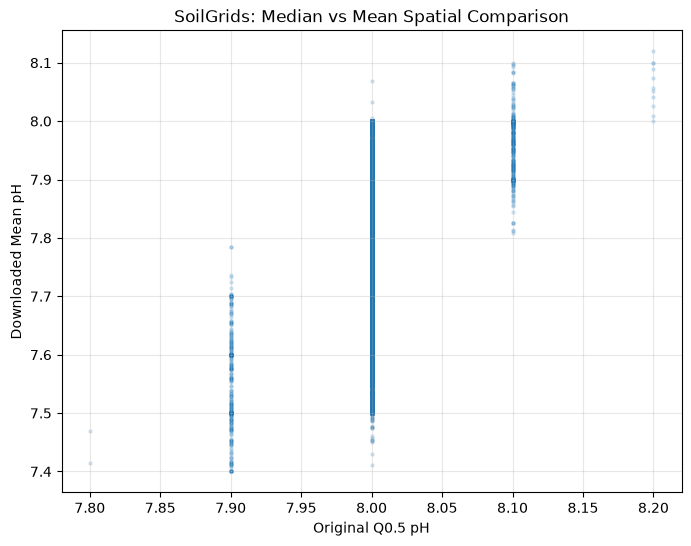

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    median_ph,
    mean_ph,
    alpha=0.15,
    s=5
)

plt.xlabel("Original Q0.5 pH")
plt.ylabel("Downloaded Mean pH")
plt.title("SoilGrids: Median vs Mean Spatial Comparison")

plt.grid(alpha=0.3)
plt.show()

In [31]:
unique, counts = np.unique(median_ph, return_counts=True)

print("Original Q0.5 distribution")
print("--------------------------")

for value, count in zip(unique, counts):
    percentage = count / len(median_ph) * 100
    print(
        f"pH {value:.1f}: "
        f"{count} pixels ({percentage:.2f}%)"
    )

Original Q0.5 distribution
--------------------------
pH 7.8: 2 pixels (0.00%)
pH 7.9: 300 pixels (0.62%)
pH 8.0: 47775 pixels (98.60%)
pH 8.1: 367 pixels (0.76%)
pH 8.2: 11 pixels (0.02%)


In [32]:
coverage_id = "phh2o_0-5cm_uncertainty"

subsets = [
    ("X", float(west_sg), float(east_sg)),
    ("Y", float(south_sg), float(north_sg))
]

response = wcs.getCoverage(
    identifier=coverage_id,
    crs="http://www.opengis.net/def/crs/EPSG/0/152160",
    subsets=subsets,
    resx=250,
    resy=250,
    format="image/tiff"
)

uncertainty_path = "../data/raw/sahiwal_phh2o_0-5cm_uncertainty.tif"

with open(uncertainty_path, "wb") as file:
    file.write(response.read())

print("Uncertainty raster downloaded!")

Uncertainty raster downloaded!


In [33]:
import rasterio
import numpy as np

with rasterio.open(uncertainty_path) as src:
    uncertainty_data = src.read(1, masked=True)

    print("Dimensions:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Data type:", src.dtypes)
    print("NoData:", src.nodata)

    print("\nUncertainty Statistics")
    print("Minimum:", uncertainty_data.min())
    print("Maximum:", uncertainty_data.max())
    print("Mean:", uncertainty_data.mean())
    print("Valid pixels:", uncertainty_data.count())

Dimensions: 315 x 304
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Interrupted_Goode_Homolosine"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Data type: ('int16',)
NoData: None

Uncertainty Statistics
Minimum: 3
Maximum: 32767
Mean: 713.2582811194653
Valid pixels: 95760


In [34]:
unique, counts = np.unique(
    uncertainty_data.compressed(),
    return_counts=True
)

print("Unique values:", len(unique))
print("\nMost frequent values:")

order = np.argsort(counts)[::-1]

for i in order[:15]:
    print(f"Value: {unique[i]}, Pixels: {counts[i]}")

print("\nPixels equal to 32767:", np.sum(uncertainty_data == 32767))


Unique values: 4

Most frequent values:
Value: 4, Pixels: 92045
Value: 32767, Pixels: 2073
Value: 5, Pixels: 1258
Value: 3, Pixels: 384

Pixels equal to 32767: 2073


In [35]:
import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling

wcs_path = uncertainty_path
website_path = tif_path

with rasterio.open(wcs_path) as wcs_src, \
     rasterio.open(website_path) as web_src:

    wcs_data = wcs_src.read(1)

    aligned_web = np.full(
        wcs_data.shape,
        -9999,
        dtype=np.int16
    )

    reproject(
        source=rasterio.band(web_src, 1),
        destination=aligned_web,
        src_transform=web_src.transform,
        src_crs=web_src.crs,
        dst_transform=wcs_src.transform,
        dst_crs=wcs_src.crs,
        dst_nodata=-9999,
        resampling=Resampling.nearest
    )

    valid = aligned_web != -9999

    a = wcs_data[valid]
    b = aligned_web[valid]

    print("WCS pixels:", len(a))
    print("Website pixels:", len(b))
    print("Exact matching pixels:", np.sum(a == b))
    print("Matching percentage:", np.mean(a == b) * 100)
    print("WCS unique values:", np.unique(a))
    print("Website unique values:", np.unique(b))
    print("Mean absolute difference:", np.mean(np.abs(a.astype(float) - b.astype(float))))

WCS pixels: 92217
Website pixels: 92217
Exact matching pixels: 0
Matching percentage: 0.0
WCS unique values: [    3     4     5 32767]
Website unique values: [ 0 74 75 76 77 78 79 80 81 82]
Mean absolute difference: 796.8449635099819


In [36]:
print("tif_path:", tif_path)

with rasterio.open(tif_path) as src:
    data = src.read(1)
    print("Dimensions:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Unique values:", np.unique(data))

tif_path: ../data/raw/out.tif
Dimensions: 415 x 286
CRS: EPSG:4326
Unique values: [ 0 74 75 76 77 78 79 80 81 82]


In [37]:
website_uncertainty_path = "../data/raw/website_ph_uncertainty.tif"

with rasterio.open(website_uncertainty_path) as src:
    data = src.read(1)

    print("Dimensions:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Unique values:", np.unique(data))
    print("Number of unique values:", len(np.unique(data)))

Dimensions: 415 x 286
CRS: EPSG:4326
Unique values: [    3     4     5 32767]
Number of unique values: 4


In [38]:
import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling

wcs_path = uncertainty_path
website_path = website_uncertainty_path

with rasterio.open(wcs_path) as wcs_src, \
     rasterio.open(website_path) as web_src:

    wcs_data = wcs_src.read(1)

    aligned_web = np.full(
        wcs_data.shape,
        -9999,
        dtype=np.int16
    )

    reproject(
        source=rasterio.band(web_src, 1),
        destination=aligned_web,
        src_transform=web_src.transform,
        src_crs=web_src.crs,
        dst_transform=wcs_src.transform,
        dst_crs=wcs_src.crs,
        resampling=Resampling.nearest,
        dst_nodata=-9999
    )

    valid = aligned_web != -9999

    a = wcs_data[valid]
    b = aligned_web[valid]

    print("Compared pixels:", len(a))
    print("Exact matches:", np.sum(a == b))
    print("Matching percentage:", round(np.mean(a == b) * 100, 2), "%")
    print("WCS distribution:", np.unique(a, return_counts=True))
    print("Website distribution:", np.unique(b, return_counts=True))
    print("Mean absolute difference:",
          np.mean(np.abs(a.astype(float) - b.astype(float))))
    

Compared pixels: 92217
Exact matches: 90581
Matching percentage: 98.23 %
WCS distribution: (array([    3,     4,     5, 32767], dtype=int16), array([  250, 88674,  1252,  2041]))
Website distribution: (array([    3,     4,     5, 32767], dtype=int16), array([  230, 88671,  1261,  2055]))
Mean absolute difference: 381.57809297634924


In [39]:
from pathlib import Path

coverage_id = "phh2o_0-5cm_mean"

subsets = [
    ("X", float(west_sg), float(east_sg)),
    ("Y", float(south_sg), float(north_sg))
]

response = wcs.getCoverage(
    identifier=coverage_id,
    crs="http://www.opengis.net/def/crs/EPSG/0/152160",
    subsets=subsets,
    resx=250,
    resy=250,
    format="image/tiff"
)

output_path = Path("../data/raw/sahiwal_phh2o_0-5cm_mean.tif")

with open(output_path, "wb") as file:
    file.write(response.read())

print("Saved:", output_path)
print("File size:", round(output_path.stat().st_size / 1024, 2), "KB")

Saved: ..\data\raw\sahiwal_phh2o_0-5cm_mean.tif
File size: 29.86 KB


In [40]:
mean_path = "../data/raw/sahiwal_phh2o_0-5cm_mean.tif"

with rasterio.open(mean_path) as src:
    mean_data = src.read(1)

    print("Dimensions:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Data type:", mean_data.dtype)
    print("Minimum:", mean_data.min())
    print("Maximum:", mean_data.max())
    print("Unique values:", np.unique(mean_data))
    print("Unique value count:", len(np.unique(mean_data)))

Dimensions: 315 x 304
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Interrupted_Goode_Homolosine"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Data type: int16
Minimum: 0
Maximum: 82
Unique values: [ 0 74 75 76 77 78 79 80 81 82]
Unique value count: 10


In [41]:
from rasterio.warp import reproject, Resampling

wcs_path = mean_path
website_path = tif_path  # out.tif: website mean

with rasterio.open(wcs_path) as wcs_src, \
     rasterio.open(website_path) as web_src:

    wcs_data = wcs_src.read(1)

    aligned_web = np.full(
        wcs_data.shape, -9999, dtype=np.int16
    )

    reproject(
        source=rasterio.band(web_src, 1),
        destination=aligned_web,
        src_transform=web_src.transform,
        src_crs=web_src.crs,
        dst_transform=wcs_src.transform,
        dst_crs=wcs_src.crs,
        resampling=Resampling.nearest,
        dst_nodata=-9999
    )

    valid = aligned_web != -9999

    a = wcs_data[valid]
    b = aligned_web[valid]

    print("Compared pixels:", len(a))
    print("Exact matches:", np.sum(a == b))
    print("Matching percentage:", round(np.mean(a == b) * 100, 2), "%")
    print("WCS distribution:", np.unique(a, return_counts=True))
    print("Website distribution:", np.unique(b, return_counts=True))
    print("Mean absolute difference:",
          np.mean(np.abs(a.astype(float) - b.astype(float))))

Compared pixels: 92217
Exact matches: 78414
Matching percentage: 85.03 %
WCS distribution: (array([ 0, 74, 75, 76, 77, 78, 79, 80, 81, 82], dtype=int16), array([ 2041,    95,   899,  5318, 12455, 36704, 30862,  3787,    55,
           1]))
Website distribution: (array([ 0, 74, 75, 76, 77, 78, 79, 80, 81, 82], dtype=int16), array([ 2055,    89,   897,  5322, 12524, 36739, 30825,  3706,    59,
           1]))
Mean absolute difference: 1.0512161532038562


In [42]:
from pathlib import Path

raw_dir = Path("../data/raw")

for file in sorted(raw_dir.glob("*.tif")):
    with rasterio.open(file) as src:
        print(
            f"{file.name:45} "
            f"{src.width}x{src.height} | "
            f"{src.crs.to_string() if src.crs else 'Unknown'}"
        )

out.tif                                       415x286 | EPSG:4326
sahiwal_phh2o_0-5cm_mean.tif                  315x304 | PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Interrupted_Goode_Homolosine"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
sahiwal_phh2o_0-5cm_Q0.5.tif                  315x304 | PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Interrupted_Goode_Homolosine"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["

In [43]:
from owslib.wcs import WebCoverageService

properties = {
    "pH": "https://maps.isric.org/mapserv?map=/map/phh2o.map",
    "SOC": "https://maps.isric.org/mapserv?map=/map/soc.map",
    "Nitrogen": "https://maps.isric.org/mapserv?map=/map/nitrogen.map",
    "Clay": "https://maps.isric.org/mapserv?map=/map/clay.map",
    "Sand": "https://maps.isric.org/mapserv?map=/map/sand.map",
    "Silt": "https://maps.isric.org/mapserv?map=/map/silt.map",
    "CEC": "https://maps.isric.org/mapserv?map=/map/cec.map"
}

for name, url in properties.items():
    try:
        service = WebCoverageService(url, version="2.0.1")
        print(f"{name}: {len(service.contents)} coverage layers found")
    except Exception as e:
        print(f"{name}: ERROR - {e}")

        

pH: 30 coverage layers found
SOC: 30 coverage layers found
Nitrogen: 30 coverage layers found
Clay: 30 coverage layers found
Sand: 30 coverage layers found
Silt: 30 coverage layers found
CEC: 30 coverage layers found


In [44]:
from owslib.wcs import WebCoverageService
from pathlib import Path

properties = {
    "pH": "https://maps.isric.org/mapserv?map=/map/phh2o.map",
    "SOC": "https://maps.isric.org/mapserv?map=/map/soc.map",
    "Nitrogen": "https://maps.isric.org/mapserv?map=/map/nitrogen.map",
    "Clay": "https://maps.isric.org/mapserv?map=/map/clay.map",
    "Sand": "https://maps.isric.org/mapserv?map=/map/sand.map",
    "Silt": "https://maps.isric.org/mapserv?map=/map/silt.map",
    "CEC": "https://maps.isric.org/mapserv?map=/map/cec.map"
}

output_dir = Path("../data/raw")
output_dir.mkdir(parents=True, exist_ok=True)

for name, url in properties.items():
    try:
        service = WebCoverageService(url, version="2.0.1")

        matching_layers = [
            layer for layer in service.contents
            if "0-5cm" in layer and layer.endswith("_mean")
        ]

        if len(matching_layers) != 1:
            print(f"{name}: Could not identify one mean layer")
            continue

        coverage_id = matching_layers[0]
        output_path = output_dir / f"sahiwal_{name.lower()}_0-5cm_mean.tif"

        if output_path.exists():
            print(f"{name}: Already downloaded, skipping")
            continue

        response = service.getCoverage(
            identifier=coverage_id,
            crs="http://www.opengis.net/def/crs/EPSG/0/152160",
            subsets=[
                ("X", float(west_sg), float(east_sg)),
                ("Y", float(south_sg), float(north_sg))
            ],
            resx=250,
            resy=250,
            format="image/tiff"
        )

        with open(output_path, "wb") as file:
            file.write(response.read())

        print(f"{name}: Downloaded successfully")

    except Exception as e:
        print(f"{name}: ERROR - {e}")

pH: Downloaded successfully
SOC: Downloaded successfully
Nitrogen: Downloaded successfully
Clay: Downloaded successfully
Sand: Downloaded successfully
Silt: Downloaded successfully
CEC: Downloaded successfully


In [45]:
from pathlib import Path
import rasterio

raw_dir = Path("../data/raw")

raster_files = sorted(
    raw_dir.glob("sahiwal_*_0-5cm_mean.tif")
)

for file in raster_files:
    with rasterio.open(file) as src:
        print(f"\n{file.name}")
        print("Shape:", src.height, "x", src.width)
        print("CRS:", src.crs)
        print("Transform:", src.transform)
        print("Data type:", src.dtypes[0])
        print("NoData:", src.nodata)


sahiwal_cec_0-5cm_mean.tif
Shape: 304 x 315
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Interrupted_Goode_Homolosine"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Transform: | 250.25, 0.00, 7412702.14|
| 0.00,-250.16, 3437904.71|
| 0.00, 0.00, 1.00|
Data type: int16
NoData: None

sahiwal_clay_0-5cm_mean.tif
Shape: 304 x 315
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Interrupted_Goode_Homolosine"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EP

In [47]:
# Purpose: Transform the Sahiwal boundary into each raster's CRS and clip all seven SoilGrids layers.

import rasterio
import json
from pathlib import Path
from rasterio.mask import mask
from rasterio.warp import transform_geom

raw_dir = Path("../data/raw")
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

boundary_path = processed_dir / "sahiwal_boundary.geojson"

properties = [
    "phh2o", "soc", "nitrogen",
    "clay", "sand", "silt", "cec"
]

with open(boundary_path) as f:
    boundary = json.load(f)

for prop in properties:
    input_path = raw_dir / f"sahiwal_{prop}_0-5cm_mean.tif"
    output_path = processed_dir / f"{prop}_clipped.tif"

    with rasterio.open(input_path) as src:

        # Convert boundary geometry from EPSG:4326 to raster CRS
        projected_geometries = [
            transform_geom(
                "EPSG:4326",
                src.crs,
                feature["geometry"]
            )
            for feature in boundary["features"]
        ]

        clipped, transform = mask(
            src,
            projected_geometries,
            crop=True,
            filled=True,
            nodata=-9999
        )

        profile = src.profile.copy()
        profile.update(
            height=clipped.shape[1],
            width=clipped.shape[2],
            transform=transform,
            nodata=-9999,
            dtype="int16"
        )

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(clipped.astype("int16"))

    print(f"{prop}: clipped successfully")

print("\nAll seven clipping operations completed.")

phh2o: clipped successfully
soc: clipped successfully
nitrogen: clipped successfully
clay: clipped successfully
sand: clipped successfully
silt: clipped successfully
cec: clipped successfully

All seven clipping operations completed.


In [48]:
# Purpose: Combine the seven clipped soil rasters into one tabular dataset with geographic coordinates.

import rasterio
import numpy as np
import pandas as pd
from pathlib import Path
from rasterio.transform import xy
from pyproj import Transformer

processed_dir = Path("../data/processed")

properties = [
    "phh2o", "soc", "nitrogen",
    "clay", "sand", "silt", "cec"
]

data = {}

# Read all seven clipped rasters
for prop in properties:
    path = processed_dir / f"{prop}_clipped.tif"

    with rasterio.open(path) as src:
        data[prop] = src.read(1)
        transform = src.transform
        raster_crs = src.crs
        nodata = src.nodata

# Identify pixels that are valid across all properties
valid_mask = np.ones(data["phh2o"].shape, dtype=bool)

for prop in properties:
    valid_mask &= data[prop] != -9999

# Get row and column positions of valid pixels
rows, cols = np.where(valid_mask)

# Convert pixel positions into projected coordinates
x, y = xy(transform, rows, cols, offset="center")

# Convert projected coordinates into longitude and latitude
transformer = Transformer.from_crs(
    raster_crs,
    "EPSG:4326",
    always_xy=True
)

longitude, latitude = transformer.transform(x, y)

# Create the combined DataFrame
soil_data = pd.DataFrame({
    "longitude": longitude,
    "latitude": latitude
})

for prop in properties:
    soil_data[prop] = data[prop][valid_mask]

# Save the dataset
output_path = processed_dir / "sahiwal_soil_dataset.csv"
soil_data.to_csv(output_path, index=False)

print("Dataset created successfully!")
print("Shape:", soil_data.shape)
print("Saved:", output_path)
print("\nFirst five rows:")
display(soil_data.head())

Dataset created successfully!
Shape: (50158, 9)
Saved: ..\data\processed\sahiwal_soil_dataset.csv

First five rows:


,longitude,latitude,phh2o,soc,nitrogen,clay,sand,silt,cec
0,73.166888,30.8821,79,79,92,252,439,309,156
1,73.169507,30.8821,78,80,92,244,432,324,153
2,73.172127,30.8821,78,84,102,238,433,329,153
3,73.174746,30.8821,79,95,111,242,412,346,154
4,73.177366,30.8821,79,94,110,242,409,349,148


In [49]:
# Purpose: Inspect missing values, zero values, data types, and statistical summaries.

import pandas as pd
import numpy as np

dataset_path = "../data/processed/sahiwal_soil_dataset.csv"

soil_data = pd.read_csv(dataset_path)

print("Dataset shape:", soil_data.shape)

print("\nData types:")
print(soil_data.dtypes)

print("\nMissing values:")
print(soil_data.isnull().sum())

print("\nZero values:")
print((soil_data == 0).sum())

print("\nStatistical summary:")
display(soil_data.describe().round(2))

Dataset shape: (50158, 9)

Data types:
longitude    float64
latitude     float64
phh2o          int64
soc            int64
nitrogen       int64
clay           int64
sand           int64
silt           int64
cec            int64
dtype: object

Missing values:
longitude    0
latitude     0
phh2o        0
soc          0
nitrogen     0
clay         0
sand         0
silt         0
cec          0
dtype: int64

Zero values:
longitude       0
latitude        0
phh2o        1351
soc          1351
nitrogen     1351
clay         1351
sand         1351
silt         1351
cec          1351
dtype: int64

Statistical summary:


,longitude,latitude,phh2o,soc,nitrogen,clay,sand,silt,cec
count,50158.00,50158.00,50158.00,50158.00,50158.00,50158.00,50158.00,50158.00,50158.00
mean,72.88,30.56,75.89,101.69,121.12,219.15,417.96,335.95,148.53
std,0.25,0.15,12.66,19.00,33.49,39.09,72.32,60.19,27.24
min,72.41,30.20,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,72.67,30.45,77.00,98.00,107.00,214.00,415.00,329.00,143.00
50%,72.89,30.56,78.00,104.00,115.00,224.00,428.00,345.00,151.00
75%,73.09,30.67,79.00,110.00,127.00,234.00,441.00,360.00,161.00
max,73.34,30.88,82.00,236.00,235.00,311.00,509.00,417.00,194.00


In [50]:
# Purpose: Identify whether zero values represent missing pixels shared across all soil properties.

soil_columns = [
    "phh2o", "soc", "nitrogen",
    "clay", "sand", "silt", "cec"
]

all_zero = (soil_data[soil_columns] == 0).all(axis=1)
any_zero = (soil_data[soil_columns] == 0).any(axis=1)

print("Rows where all seven properties are zero:", all_zero.sum())
print("Rows where at least one property is zero:", any_zero.sum())
print("Rows with no zero values:", (~any_zero).sum())

print("\nSample rows containing zero values:")
display(soil_data[any_zero].head(10))

Rows where all seven properties are zero: 1351
Rows where at least one property is zero: 1351
Rows with no zero values: 48807

Sample rows containing zero values:


,longitude,latitude,phh2o,soc,nitrogen,clay,sand,silt,cec
40,73.151767,30.877605,0,0,0,0,0,0,0
431,73.111836,30.852886,0,0,0,0,0,0,0
432,73.114455,30.852886,0,0,0,0,0,0,0
433,73.117073,30.852886,0,0,0,0,0,0,0
542,73.107198,30.848391,0,0,0,0,0,0,0
601,73.108806,30.846144,0,0,0,0,0,0,0
660,73.110415,30.843897,0,0,0,0,0,0,0
661,73.113033,30.843897,0,0,0,0,0,0,0
720,73.112024,30.841649,0,0,0,0,0,0,0
781,73.113632,30.839402,0,0,0,0,0,0,0


In [51]:
# Purpose: Remove pixels with missing soil measurements and save the cleaned dataset.

soil_columns = [
    "phh2o", "soc", "nitrogen",
    "clay", "sand", "silt", "cec"
]

before = len(soil_data)

clean_soil_data = soil_data[
    (soil_data[soil_columns] != 0).all(axis=1)
].copy()

removed = before - len(clean_soil_data)

output_path = "../data/processed/sahiwal_soil_dataset_clean.csv"

clean_soil_data.to_csv(output_path, index=False)

print("Original observations:", before)
print("Removed invalid observations:", removed)
print("Remaining observations:", len(clean_soil_data))
print("Remaining missing values:", clean_soil_data.isnull().sum().sum())
print("Saved:", output_path)

display(clean_soil_data.head())

Original observations: 50158
Removed invalid observations: 1351
Remaining observations: 48807
Remaining missing values: 0
Saved: ../data/processed/sahiwal_soil_dataset_clean.csv


,longitude,latitude,phh2o,soc,nitrogen,clay,sand,silt,cec
0,73.166888,30.8821,79,79,92,252,439,309,156
1,73.169507,30.8821,78,80,92,244,432,324,153
2,73.172127,30.8821,78,84,102,238,433,329,153
3,73.174746,30.8821,79,95,111,242,412,346,154
4,73.177366,30.8821,79,94,110,242,409,349,148


In [52]:
# Purpose: Inspect the raw value ranges of each SoilGrids property before applying scale factors.

soil_columns = [
    "phh2o", "soc", "nitrogen",
    "clay", "sand", "silt", "cec"
]

for col in soil_columns:
    print(f"\n{col.upper()}")
    print("Minimum:", clean_soil_data[col].min())
    print("Maximum:", clean_soil_data[col].max())
    print("Mean:", round(clean_soil_data[col].mean(), 2))
    print("Median:", clean_soil_data[col].median())


PHH2O
Minimum: 74
Maximum: 82
Mean: 77.99
Median: 78.0

SOC
Minimum: 64
Maximum: 236
Mean: 104.51
Median: 104.0

NITROGEN
Minimum: 78
Maximum: 235
Mean: 124.47
Median: 115.0

CLAY
Minimum: 183
Maximum: 311
Mean: 225.22
Median: 224.0

SAND
Minimum: 362
Maximum: 509
Mean: 429.53
Median: 428.0

SILT
Minimum: 251
Maximum: 417
Mean: 345.25
Median: 346.0

CEC
Minimum: 114
Maximum: 194
Mean: 152.64
Median: 152.0


In [53]:
# Purpose: Convert raw SoilGrids integer values into conventional scientific units and save the scaled dataset.

scaled_soil_data = clean_soil_data.copy()

scaled_soil_data["ph"] = scaled_soil_data["phh2o"] / 10
scaled_soil_data["soc_g_kg"] = scaled_soil_data["soc"] / 10
scaled_soil_data["nitrogen_g_kg"] = scaled_soil_data["nitrogen"] / 100

scaled_soil_data["clay_pct"] = scaled_soil_data["clay"] / 10
scaled_soil_data["sand_pct"] = scaled_soil_data["sand"] / 10
scaled_soil_data["silt_pct"] = scaled_soil_data["silt"] / 10

scaled_soil_data["cec_cmol_kg"] = scaled_soil_data["cec"] / 10

# Remove the original scaled integer columns
scaled_soil_data = scaled_soil_data.drop(columns=[
    "phh2o", "soc", "nitrogen",
    "clay", "sand", "silt", "cec"
])

# Save the converted dataset
output_path = "../data/processed/sahiwal_soil_dataset_scaled.csv"

scaled_soil_data.to_csv(output_path, index=False)

print("Scaled dataset created!")
print("Shape:", scaled_soil_data.shape)

display(scaled_soil_data.head())
display(scaled_soil_data.describe().round(3))

Scaled dataset created!
Shape: (48807, 9)


,longitude,latitude,ph,soc_g_kg,nitrogen_g_kg,clay_pct,sand_pct,silt_pct,cec_cmol_kg
0,73.166888,30.8821,7.9,7.9,0.92,25.2,43.9,30.9,15.6
1,73.169507,30.8821,7.8,8.0,0.92,24.4,43.2,32.4,15.3
2,73.172127,30.8821,7.8,8.4,1.02,23.8,43.3,32.9,15.3
3,73.174746,30.8821,7.9,9.5,1.11,24.2,41.2,34.6,15.4
4,73.177366,30.8821,7.9,9.4,1.10,24.2,40.9,34.9,14.8


,longitude,latitude,ph,soc_g_kg,nitrogen_g_kg,clay_pct,sand_pct,silt_pct,cec_cmol_kg
count,48807.000,48807.000,48807.000,48807.000,48807.000,48807.000,48807.000,48807.000,48807.000
mean,72.880,30.555,7.799,10.451,1.245,22.522,42.953,34.525,15.264
std,0.246,0.146,0.098,0.876,0.271,1.429,2.014,2.263,1.162
min,72.406,30.201,7.400,6.400,0.780,18.300,36.200,25.100,11.400
25%,72.668,30.451,7.800,9.900,1.080,21.500,41.600,33.000,14.300
50%,72.888,30.558,7.800,10.400,1.150,22.400,42.800,34.600,15.200
75%,73.090,30.664,7.900,11.000,1.280,23.400,44.100,36.100,16.100
max,73.342,30.882,8.200,23.600,2.350,31.100,50.900,41.700,19.400
